# Horizon vs map coverage

Goal: pick a `HORIZON` so the supervised future trajectory covers the BEV grid well:
- **coverage**: most poses should land inside the grid. Fraction of all supervised poses
- **reach**: path reaches far enough into grid to label distant cells. forward (ego-x) distance the path has travelled by step `H`.

In [17]:
import contextlib
import io
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from config.paths import EXTRACTED_ROOT, ROS1_ROOT
from data_labeling_pipeline.dataset_loader import GrandTourLoader


cfg = yaml.safe_load(Path("../configs/grandtour.yaml").read_text())
DT = cfg["TRAINING"]["DT"]
H_CFG = cfg["TRAINING"]["HORIZON"]  # currently configured horizon
HMAX = 300  # analysis sweep range (independent of the chosen horizon)
gb = cfg["MODEL"]["GRID_BOUNDS"]
XB, YB = gb["xbound"][:2], gb["ybound"][:2]
X_FWD = XB[1]  # forward grid extent [m]

DOC_FIG = Path("../../../documentation/figures")
DOC_FIG.mkdir(parents=True, exist_ok=True)

missions = sorted(
    p.name
    for p in EXTRACTED_ROOT.iterdir()
    if (p / "dlio_odom.npy").exists() and (p / "command.npy").exists()
)
missions = [m for m in missions if m != "ICE-1"]  # unreliable data
print(
    len(missions),
    "missions",
    "| grid x",
    XB,
    "y",
    YB,
    "| sweep",
    HMAX,
    "| configured H",
    H_CFG,
)

48 missions | grid x [-2.0, 8.0] y [-5.0, 5.0] | sweep 300 | configured H 200


In [18]:
def load_poses(mission: str) -> np.ndarray:
    """(N, 3) [x, y, yaw] DLIO poses on the uniform dt grid."""
    loader = GrandTourLoader(ROS1_ROOT / mission)
    with contextlib.redirect_stdout(io.StringIO()):
        _, _, Z = loader.load_data_shared_timestamps(dt=DT)
    return Z


def marginal_in_grid(Z: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Per offset k: count and total of poses landing in-grid, over all anchors."""
    x, y, yaw = Z[:, 0], Z[:, 1], Z[:, 2]
    n = len(Z)
    hits = np.zeros(HMAX)
    tot = np.zeros(HMAX)
    for k in range(min(HMAX, n)):
        a = slice(0, n - k)
        dx, dy = x[k:] - x[a], y[k:] - y[a]
        c, s = np.cos(yaw[a]), np.sin(yaw[a])
        xr, yr = c * dx + s * dy, -s * dx + c * dy
        ok = (xr >= XB[0]) & (xr <= XB[1]) & (yr >= YB[0]) & (yr <= YB[1])
        hits[k], tot[k] = ok.sum(), ok.size
    return hits, tot


def reach_windows(Z: np.ndarray) -> np.ndarray | None:
    """Deepest in-grid forward reach (A, HMAX): cumulative max of ego-x while in grid."""
    x, y, yaw = Z[:, 0], Z[:, 1], Z[:, 2]
    n_anchors = len(Z) - HMAX
    if n_anchors <= 0:
        return None
    a = np.arange(n_anchors)[:, None]
    t = a + np.arange(HMAX)[None, :]
    dx, dy = x[t] - x[a], y[t] - y[a]
    c, s = np.cos(yaw[a]), np.sin(yaw[a])
    xr, yr = c * dx + s * dy, -s * dx + c * dy
    ing = (xr >= XB[0]) & (xr <= XB[1]) & (yr >= YB[0]) & (yr <= YB[1])
    return np.maximum.accumulate(np.where(ing, xr, 0.0), axis=1).astype(np.float32)


per_mission = {}
hits = np.zeros(HMAX)
tot = np.zeros(HMAX)
reach_cols = []
steps = np.arange(1, HMAX + 1)
for m in missions:
    Z = load_poses(m)
    h, t = marginal_in_grid(Z)
    per_mission[m] = np.cumsum(h) / np.cumsum(t)  # % poses in grid within 0..H window
    hits += h
    tot += t
    xr = reach_windows(Z)
    if xr is not None:
        reach_cols.append(xr)

coverage = np.cumsum(hits) / np.cumsum(tot)  # pooled % of supervised poses in grid
REACH = np.concatenate(reach_cols)  # (anchors, HMAX) deepest in-grid forward reach
reach_p25, reach_med, reach_p75 = np.percentile(REACH, [25, 50, 75], axis=0)
# Deep-reach: fraction of anchors whose path reaches the mid / far grid by step H.
NEAR, FAR = 4.0, 6.0  # forward thresholds [m]; the in-grid edge sits at 8 m
reach_ge_near = (REACH >= NEAR).mean(0)
reach_ge_far = (REACH >= FAR).mean(0)
print(f"{len(per_mission)} missions, {int(tot[0])} anchors pooled")

48 missions, 175734 anchors pooled


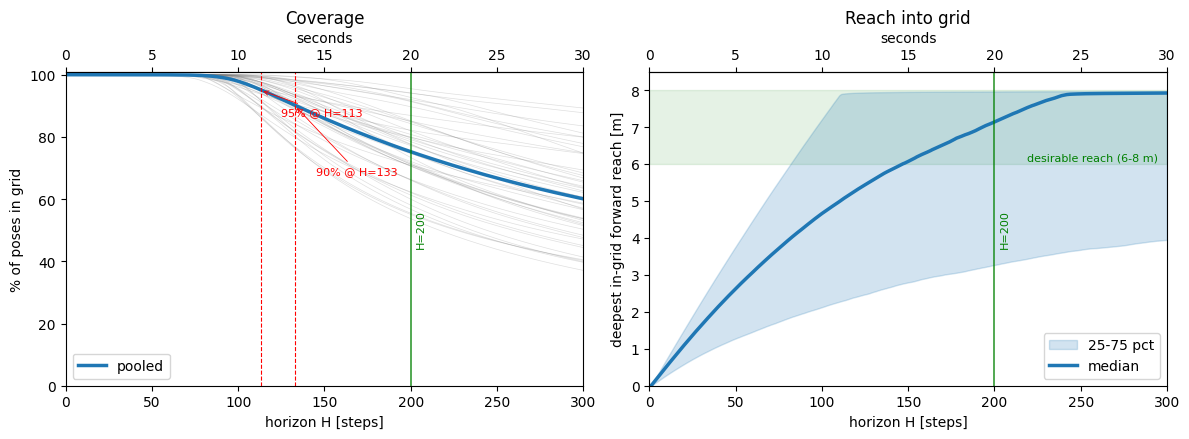

In [19]:
fig, (axc, axr) = plt.subplots(1, 2, figsize=(12, 4.5))

for cov in per_mission.values():
    axc.plot(steps, 100 * cov, color="grey", lw=0.5, alpha=0.25)
axc.plot(steps, 100 * coverage, color="tab:blue", lw=2.5, label="pooled")
for i, thr in enumerate((0.95, 0.90)):
    h = int(steps[coverage >= thr][-1]) if (coverage >= thr).any() else 0
    axc.axvline(h, color="red", ls="--", lw=0.8)
    axc.annotate(
        f"{int(thr * 100)}% @ H={h}",
        xy=(h, 100 * thr),
        xytext=(h + 12, 100 * thr - 8 - 14 * i),
        color="red",
        fontsize=8,
        arrowprops=dict(arrowstyle="->", color="red", lw=0.6),
    )
axc.set(
    xlabel="horizon H [steps]",
    ylabel="% of poses in grid",
    title="Coverage",
    xlim=(0, HMAX),
    ylim=(0, 101),
)
axc.legend(loc="lower left")

axr.axhspan(X_FWD * 0.75, X_FWD, color="green", alpha=0.10)
axr.text(
    HMAX - 5,
    X_FWD * 0.75 + 0.05,
    "desirable reach (6-8 m)",
    color="green",
    fontsize=8,
    ha="right",
    va="bottom",
)
axr.fill_between(
    steps, reach_p25, reach_p75, color="tab:blue", alpha=0.2, label="25-75 pct"
)
axr.plot(steps, reach_med, color="tab:blue", lw=2.5, label="median")
axr.set(
    xlabel="horizon H [steps]",
    ylabel="deepest in-grid forward reach [m]",
    title="Reach into grid",
    xlim=(0, HMAX),
    ylim=(0, X_FWD + 0.5),
)
axr.legend(loc="lower right")

for ax in (axc, axr):
    ax.axvline(H_CFG, color="green", lw=1.2, alpha=0.8)
    ax.text(
        H_CFG + 3,
        ax.get_ylim()[1] * 0.5,
        f"H={H_CFG}",
        color="green",
        fontsize=8,
        rotation=90,
        va="center",
    )
    ax.secondary_xaxis(
        "top", functions=(lambda s: s * DT, lambda t: t / DT)
    ).set_xlabel("seconds")
fig.tight_layout()
fig.savefig(DOC_FIG / "horizon_tradeoff.pdf", bbox_inches="tight")
plt.show()

In [20]:
cands = [50, 75, 100, 125, 150, 185, 200, 225, 250, 275, 300]
df = pd.DataFrame({
    "HORIZON": cands,
    "seconds": [f"{h * DT:.1f}" for h in cands],
    "coverage_pct": [f"{100 * coverage[h - 1]:.1f}" for h in cands],
    "reach_median_m": [f"{reach_med[h - 1]:.2f}" for h in cands],
    "reach_ge4_pct": [f"{100 * reach_ge_near[h - 1]:.1f}" for h in cands],
    "reach_ge6_pct": [f"{100 * reach_ge_far[h - 1]:.1f}" for h in cands],
})

latex = df.to_latex(
    index=False,
    caption=(
        "Prediction-horizon trade-off, pooled over all 48 missions. Coverage is the "
        "fraction of supervised poses inside the grid; reach is the deepest in-grid "
        "forward distance the path attains. The last two columns give the fraction "
        "of anchors whose path reaches the mid (4\\,m) and far (6\\,m) grid."
    ),
    label="tab:horizon",
    column_format="rrrrrr",
    header=[
        "$H$",
        "seconds",
        "coverage [\\%]",
        "median reach [m]",
        "$\\ge 4$\\,m [\\%]",
        "$\\ge 6$\\,m [\\%]",
    ],
    position="htbp",
)
(DOC_FIG / "horizon_table.tex").write_text(latex)
df

,HORIZON,seconds,coverage_pct,reach_median_m,reach_ge4_pct,reach_ge6_pct
0,50,5.0,100.0,2.62,17.8,0.0
1,75,7.5,99.9,3.72,46.4,16.5
2,100,10.0,97.9,4.66,56.7,37.4
3,125,12.5,92.2,5.44,62.3,45.5
4,150,15.0,86.0,6.07,65.8,50.5
5,185,18.5,78.2,6.82,69.0,55.8
6,200,20.0,75.3,7.14,70.1,57.4
7,225,22.5,70.8,7.63,71.6,59.3
8,250,25.0,66.8,7.90,72.9,60.8
9,275,27.5,63.2,7.91,73.8,62.0
